# 00b · Medición de la frecuencia de refresco de las cámaras

## Motivación / Objetivos

Un ciclo semafórico urbano dura ~60–120 s. Si se captura una imagen cada 30–60 s, solo se obtienen 1–2 muestras por ciclo: no se pueden medir duraciones de fase ni seguir peatones o vehículos entre fotogramas. Para diseñar la captura hay que saber **cada cuánto publica el servidor una imagen nueva**.

Objetivos:
- Medir el refresco real de varias cámaras de referencia.
- Comprobar si la cabecera `Last-Modified` es fiable como marca temporal de la imagen.
- Decidir la frecuencia de captura según la tabla siguiente.

| Mediana del refresco | Consecuencia |
|---|---|
| ≤ 5 s | Captura de alta frecuencia en 3–5 cámaras de referencia → medir duraciones de fase directamente. |
| 5–20 s | Duraciones con incertidumbre ± refresco; combinar con el enfoque estadístico. |
| > 20 s | Enfoque estadístico: fracción de rojo/verde a partir de muchas muestras con fase aleatoria. |

**Objetivos del TFM relacionados:** OE-4 (estado y tiempos de los semáforos).

## Método

El servidor de imágenes (`ctraficomovilidad.malaga.eu`) devuelve la cabecera HTTP `Last-Modified` en las peticiones GET (no en HEAD). Se consultan varias cámaras cada `POLL_S` segundos y se registra:

- `Last-Modified`: instante exacto en que el servidor publicó la imagen.
- SHA-1 del contenido: método de respaldo si faltara la cabecera (precisión limitada a `POLL_S`).

El código de medición está en `scripts/medir_refresco.py`. `captura_camaras.py` guarda `server_last_modified` en cada captura, así que el refresco también se puede analizar de forma pasiva (paso 4).

1. Configuración.
2. Medición activa (o carga de la última medición).
3. Distribución de intervalos entre imágenes nuevas.
4. Análisis pasivo sobre la captura continua.

### 1. Configuración

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import medir_refresco as mr
from config import load_config, path

CAMERAS = load_config()["refresco"]["camaras_referencia"]  # config.yaml
DURATION_MIN = 10   # minutos de medición
POLL_S = 1.0        # segundos entre consultas
SAVE_IMAGES = True  # guarda cada imagen nueva (útil para ver el ciclo semafórico a alta frecuencia)

print("Salida:", mr.OUT_DIR)

Matplotlib is building the font cache; this may take a moment.


Salida: C:\Users\loren\OneDrive\Escritorio\MASTER-UIMP\TFM\tfm\data\malaga\refresco


### 2. Medición activa

Tarda `DURATION_MIN` minutos. Si ya existe una medición previa, se puede saltar la primera celda y cargar el CSV con la segunda.

In [2]:
polls, summary = mr.measure(CAMERAS, DURATION_MIN, POLL_S, save_images=SAVE_IMAGES)
display(summary)

Midiendo 5 cámaras cada 1.0s durante 10 min...


Consultas guardadas en C:\Users\loren\OneDrive\Escritorio\MASTER-UIMP\TFM\tfm\data\malaga\refresco\refresco_20261012T230803Z.csv


,camera_id,method,n_intervalos,mean,std,min,p10_s,mediana_s,p90_s,max,poll_s,antiguedad_mediana_s
0,21541,hash,99.0,5.948653,1.813789,2.000125,3.808063,6.004220,8.056033,9.973575,1.0,3.072485
1,21541,last_modified,100.0,5.940000,1.698603,2.000000,3.000000,6.000000,8.000000,9.000000,1.0,3.072485
2,21545,hash,101.0,5.840836,1.796508,1.000883,4.000773,6.004431,8.002935,9.692197,1.0,3.020920
3,21545,last_modified,100.0,5.940000,1.625678,2.000000,4.000000,6.000000,8.000000,9.000000,1.0,3.020920
4,21547,hash,101.0,5.830902,1.796507,1.000608,3.002406,6.003742,8.015215,9.009820,1.0,3.283842
5,21547,last_modified,100.0,5.940000,1.613203,2.000000,4.000000,6.000000,8.000000,9.000000,1.0,3.283842
6,21560,hash,101.0,5.830849,1.829518,0.999273,3.286008,6.003906,8.006289,9.974045,1.0,3.071611
7,21560,last_modified,100.0,5.940000,1.698603,2.000000,3.000000,6.000000,8.000000,9.000000,1.0,3.071611
8,21563,hash,99.0,5.958836,1.677897,2.000961,4.001226,6.004344,8.159801,9.692280,1.0,3.055680
9,21563,last_modified,100.0,5.940000,1.613203,2.000000,4.000000,6.000000,8.000000,9.000000,1.0,3.055680


In [3]:
# Cargar la última medición disponible (reanalizar sin volver a medir)
polls_file = sorted(mr.OUT_DIR.glob("refresco_*Z.csv"))[-1]
polls = pd.read_csv(polls_file, parse_dates=["requested_at", "last_modified"])
print("Medición:", polls_file.name, "| consultas:", len(polls))

errores = polls[polls["status"].astype(str) != "200"]
print(f"Consultas con error: {len(errores)} ({100 * len(errores) / len(polls):.1f}%)")

intervals = mr.change_intervals(polls)
summary = mr.summarize(polls, POLL_S)
display(summary)

Medición: refresco_20261012T230803Z.csv | consultas: 2750
Consultas con error: 0 (0.0%)


,camera_id,method,n_intervalos,mean,std,min,p10_s,mediana_s,p90_s,max,poll_s,antiguedad_mediana_s
0,21541,hash,99.0,5.948653,1.813789,2.000125,3.808063,6.004220,8.056033,9.973575,1.0,3.072485
1,21541,last_modified,100.0,5.940000,1.698603,2.000000,3.000000,6.000000,8.000000,9.000000,1.0,3.072485
2,21545,hash,101.0,5.840836,1.796508,1.000883,4.000773,6.004431,8.002935,9.692197,1.0,3.020920
3,21545,last_modified,100.0,5.940000,1.625678,2.000000,4.000000,6.000000,8.000000,9.000000,1.0,3.020920
4,21547,hash,101.0,5.830902,1.796507,1.000608,3.002406,6.003742,8.015215,9.009820,1.0,3.283842
5,21547,last_modified,100.0,5.940000,1.613203,2.000000,4.000000,6.000000,8.000000,9.000000,1.0,3.283842
6,21560,hash,101.0,5.830849,1.829518,0.999273,3.286008,6.003906,8.006289,9.974045,1.0,3.071611
7,21560,last_modified,100.0,5.940000,1.698603,2.000000,3.000000,6.000000,8.000000,9.000000,1.0,3.071611
8,21563,hash,99.0,5.958836,1.677897,2.000961,4.001226,6.004344,8.159801,9.692280,1.0,3.055680
9,21563,last_modified,100.0,5.940000,1.613203,2.000000,4.000000,6.000000,8.000000,9.000000,1.0,3.055680


### 3. Distribución de intervalos entre imágenes nuevas

Si ambos métodos coinciden, `Last-Modified` es fiable y puede usarse como marca temporal real de la imagen (más precisa que la hora de descarga).

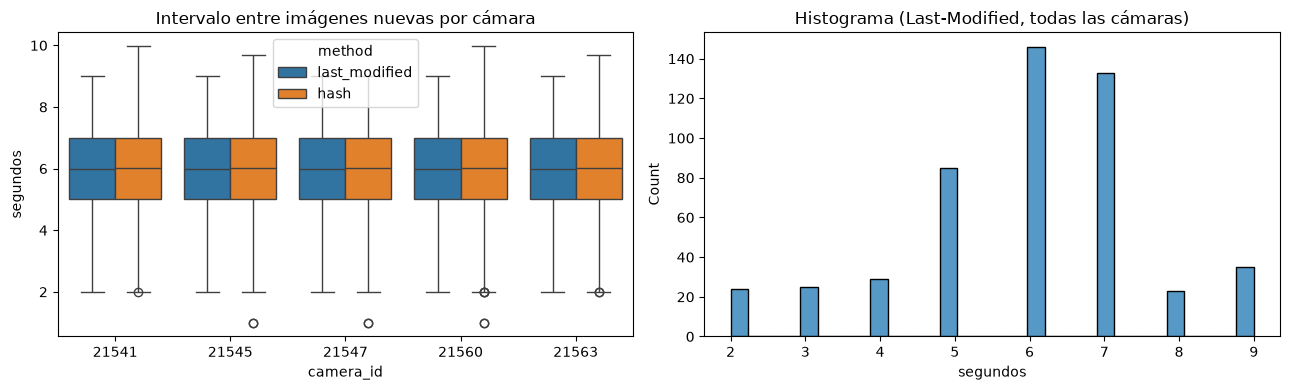

Refresco mediano global: 6.0 s


In [4]:
if intervals.empty:
    print("No se detectaron cambios de imagen: ampliar DURATION_MIN.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    sns.boxplot(data=intervals, x="camera_id", y="interval_s", hue="method", ax=axes[0])
    axes[0].set_title("Intervalo entre imágenes nuevas por cámara")
    axes[0].set_ylabel("segundos")

    sns.histplot(data=intervals[intervals["method"] == "last_modified"], x="interval_s", bins=30, ax=axes[1])
    axes[1].set_title("Histograma (Last-Modified, todas las cámaras)")
    axes[1].set_xlabel("segundos")
    plt.tight_layout()
    plt.show()

    refresco = intervals[intervals["method"] == "last_modified"]["interval_s"].median()
    print(f"Refresco mediano global: {refresco:.1f} s")

### 4. Análisis pasivo sobre la captura continua

Con los metadatos de `captura_camaras.py` (columna `server_last_modified`) se obtiene la **antigüedad** de cada imagen al descargarla y si dos capturas consecutivas son la misma imagen (captura redundante).

In [5]:
meta_files = sorted(path("metadata").glob("capturas_*.csv"))
meta = pd.concat([pd.read_csv(f) for f in meta_files], ignore_index=True) if meta_files else pd.DataFrame()

if meta.empty or meta.get("server_last_modified", pd.Series(dtype=str)).isna().all():
    print("Aún no hay capturas con server_last_modified (las capturas anteriores a la migración UTC no lo registraban).")
else:
    meta = meta[meta["status"] == "OK"].copy()
    meta["capture_time"] = pd.to_datetime(meta["capture_time"], utc=True)
    meta["server_last_modified"] = pd.to_datetime(meta["server_last_modified"], utc=True)
    meta = meta.dropna(subset=["server_last_modified"]).sort_values(["camera_id", "capture_time"])

    meta["antiguedad_s"] = (meta["capture_time"] - meta["server_last_modified"]).dt.total_seconds()
    meta["repetida"] = meta.groupby("camera_id")["server_last_modified"].diff().dt.total_seconds().eq(0)

    print(f"Capturas analizadas: {len(meta)}")
    print(f"Antigüedad mediana de la imagen al descargarla: {meta['antiguedad_s'].median():.1f} s")
    print(f"Capturas repetidas (misma imagen que la anterior): {100 * meta['repetida'].mean():.1f}%")
    display(meta.groupby("camera_id")["antiguedad_s"].describe())

Capturas analizadas: 864
Antigüedad mediana de la imagen al descargarla: 2.0 s
Capturas repetidas (misma imagen que la anterior): 0.0%


,count,mean,std,min,25%,50%,75%,max
camera_id,,,,,,,,
21541,36.0,2.555556,2.489342,-1.0,0.75,2.0,4.00,9.0
21545,36.0,2.805556,2.278087,0.0,1.00,3.0,4.00,8.0
21547,36.0,2.638889,2.205872,0.0,1.00,2.0,4.00,9.0
21554,36.0,2.638889,2.126738,-1.0,1.00,2.0,4.00,8.0
21556,36.0,2.694444,2.352135,0.0,1.00,2.0,4.00,9.0
21560,36.0,3.138889,2.269711,0.0,1.00,3.0,4.25,8.0
21563,36.0,2.694444,2.175440,0.0,1.00,2.0,4.00,8.0
21564,36.0,2.750000,2.309917,-1.0,1.00,3.0,4.00,8.0
21568,36.0,2.694444,2.290595,0.0,1.00,2.0,4.00,9.0


## Salida / Resultados

| Salida | Contenido |
|---|---|
| `data/malaga/refresco/refresco_<UTC>.csv` | Cada consulta: cámara, instante, `Last-Modified`, hash. |
| `data/malaga/refresco/refresco_<UTC>_resumen.csv` | Estadísticos del refresco por cámara y método. Lo leen `02a` y `05`. |

**Medición del 12/10/2026** (cámaras 21541, 21545, 21547, 21560 y 21563; 10 min a 1 consulta/s; 2.750 consultas, 0 errores):

- Refresco **mediano de 6,0 s** en las 5 cámaras y con ambos métodos (p10 = 3–4 s, p90 = 8 s).
- Antigüedad mediana de la imagen al descargarla: ~3 s.
- Análisis pasivo (864 capturas de las 24 cámaras del servicio): antigüedad mediana de 2 s y 0 % de capturas repetidas.

## Observaciones

- **Decisión para OE-4:** el refresco cae en la franja de 5–20 s. Se capturan las 5 cámaras de referencia cada 6 s, solo en hora punta, para limitar el volumen (`config.yaml` → `captura.alta_frecuencia`). Las duraciones de fase tendrán una incertidumbre de ±6 s, así que `05` las combina con la fracción de tiempo en cada estado.
- `Last-Modified` y el hash coinciden, así que la cabecera es fiable. El servicio la usa para no guardar imágenes repetidas (`descartar_sin_cambios`).
- En el análisis pasivo aparecen antigüedades negativas (hasta −4 s en la 75093). Es el desfase entre el reloj del portátil y el del servidor, y no afecta al refresco, que se calcula con diferencias del mismo reloj.
- La medición dura 10 minutos y se hizo a una sola hora (01:08 hora local). Conviene repetirla en hora punta para confirmar que el refresco no cambia con la carga del servidor.